In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(17)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
def center_crop(tensor, height, width):
    h, w = tensor.shape[-2:]
    if h < height or w < width:
        raise ValueError("La zone demandée dépasse le tenseur.")
    top, left = (h - height) // 2, (w - width) // 2
    return tensor[..., top:top + height, left:left + width]

def double_conv(inputs, outputs):
    return nn.Sequential(
        nn.Conv2d(inputs, outputs, 3), nn.ReLU(),
        nn.Conv2d(outputs, outputs, 3), nn.ReLU(),
    )

class UNet(nn.Module):
    def __init__(self, in_channels=1, classes=2, base=64):
        super().__init__()
        widths = [base * 2**i for i in range(5)]
        self.down = nn.ModuleList()
        inputs = in_channels
        for width in widths[:-1]:
            self.down.append(double_conv(inputs, width))
            inputs = width
        self.pool = nn.MaxPool2d(2)
        self.bottom = nn.Sequential(double_conv(widths[-2], widths[-1]), nn.Dropout(0.5))
        self.up = nn.ModuleList()
        self.decode = nn.ModuleList()
        for i in range(4, 0, -1):
            self.up.append(nn.ConvTranspose2d(widths[i], widths[i-1], 2, stride=2))
            self.decode.append(double_conv(2 * widths[i-1], widths[i-1]))
        self.head = nn.Conv2d(base, classes, 1)
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        skips = []
        for block in self.down:
            x = block(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottom(x)
        for up, block, skip in zip(self.up, self.decode, reversed(skips)):
            x = up(x)
            skip = center_crop(skip, *x.shape[-2:])
            x = block(torch.cat([skip, x], dim=1))
        return self.head(x)  # logits : batch × classes × hauteur × largeur

In [3]:
with torch.device("meta"):
    original = UNet()
    result = original(torch.empty(1, 1, 572, 572))
    assert tuple(result.shape) == (1, 2, 388, 388)
    print("Dimensions de la figure 1 :", tuple(result.shape))

Dimensions de la figure 1 : (1, 2, 388, 388)


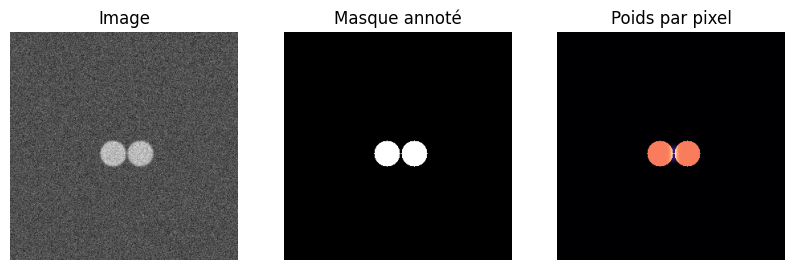

In [4]:
def make_example(seed, size=284):
    rng = np.random.default_rng(seed)
    yy, xx = np.ogrid[:size, :size]
    cy, cx = rng.integers(size//2-12, size//2+13, size=2)
    r = int(rng.integers(12, 21))
    vertical = bool(rng.integers(2))
    objects = []
    for offset in (-r-1, r+1):
        y = cy + (offset if vertical else 0)
        x = cx + (0 if vertical else offset)
        objects.append((yy-y)**2 + (xx-x)**2 <= r*r)
    mask = np.logical_or(*objects)
    distances = []
    for obj in objects:
        boundary = obj ^ ndi.binary_erosion(obj)
        distances.append(ndi.distance_transform_edt(~boundary))
    d1_plus_d2 = sum(distances)  # il y a exactement deux objets
    frequency = mask.mean()
    class_weights = np.where(mask, 0.5/frequency, 0.5/(1-frequency))
    weights = class_weights + 10*np.exp(-(d1_plus_d2**2)/(2*5**2))
    image = 0.2 + ndi.gaussian_filter(mask.astype(float), 1)*0.6
    image += rng.normal(0, 0.1, image.shape)
    return (torch.tensor(image, dtype=torch.float32)[None, None],
            torch.tensor(mask, dtype=torch.long)[None],
            torch.tensor(weights, dtype=torch.float32)[None])

image, mask, weights = make_example(0)
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, data, title in zip(axes, [image[0,0], mask[0], weights[0]],
                           ["Image", "Masque annoté", "Poids par pixel"]):
    ax.imshow(data, cmap="gray" if title != "Poids par pixel" else "magma")
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 3. Apprendre puis prédire
La cross-entropie reçoit les logits directement. La cible et les poids sont recadrés sur la même région centrale. La division par la somme des poids stabilise l’échelle de la perte. Le taux d’apprentissage et les 30 mises à jour sont des choix pour la démonstration. L’IoU affichée concerne uniquement le premier plan d’une image synthétique réservée.

In [5]:
model = UNet(base=8).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.003, momentum=0.99)
model.train()
for step in range(30):
    image, target, weight = (v.to(device) for v in make_example(step))
    optimizer.zero_grad()
    logits = model(image)
    h, w = logits.shape[-2:]
    target = center_crop(target, h, w)
    weight = center_crop(weight, h, w)
    per_pixel = F.cross_entropy(logits, target, reduction="none")
    loss = (weight * per_pixel).sum() / weight.sum()
    loss.backward()
    optimizer.step()
    if (step + 1) % 10 == 0:
        print(f"Mise à jour {step+1} | perte {loss.item():.4f}")

Mise à jour 10 | perte 0.2546
Mise à jour 20 | perte 0.2633
Mise à jour 30 | perte 0.2431


IoU de démonstration : 0.226


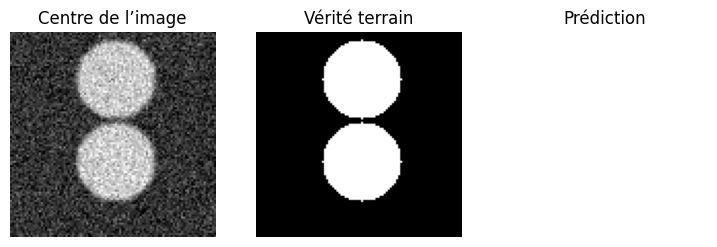

In [6]:
model.eval()
image, target, _ = make_example(1000)
with torch.no_grad():
    logits = model(image.to(device)).cpu()
prediction = logits.argmax(dim=1)
h, w = prediction.shape[-2:]
truth = center_crop(target, h, w).bool()
detected = prediction.bool()
iou = (truth & detected).sum() / (truth | detected).sum().clamp_min(1)
print(f"IoU de démonstration : {iou.item():.3f}")
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, data, title in zip(axes, [center_crop(image[0,0], h, w), truth[0], detected[0]],
                           ["Centre de l’image", "Vérité terrain", "Prédiction"]):
    ax.imshow(data, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()